In [1]:
import glob, json, ast, numpy as np, pandas as pd
from scipy.signal import welch
from scipy.stats import wilcoxon, linregress

X    = np.load('outputs/cnn_X.npy', mmap_mode='r')
meta = pd.read_csv('outputs/cnn_meta.csv')
print('X:', X.shape, '| meta:', meta.shape)

# ---- ดึง CHANS กับ SF_NEW จาก 05a ----
CHANS, SF_NEW = None, None
for nb in [f for f in glob.glob('**/*.ipynb', recursive=True) if '05a' in f.lower()]:
    for c in json.load(open(nb, encoding='utf-8'))['cells']:
        try:
            tree = ast.parse(''.join(c.get('source', [])))
        except SyntaxError:
            continue
        for node in tree.body:
            if isinstance(node, ast.Assign):
                tgt = []
                for t in node.targets:
                    tgt += [t.id] if isinstance(t, ast.Name) else \
                           [e.id for e in getattr(t, 'elts', []) if isinstance(e, ast.Name)]
                if {'CHANS', 'SF_NEW'} & set(tgt):
                    try:
                        exec(ast.unparse(node), globals())
                    except Exception:
                        pass
    if CHANS is not None:
        print('ได้ CHANS จาก', nb); break

if SF_NEW is None:
    SF_NEW = 128                      # 512 samples ÷ 4 วินาที
assert CHANS is not None and len(CHANS) == 20, 'ไม่เจอ CHANS — ก๊อปจาก 05a มาวางตรงนี้'
print('SF_NEW =', SF_NEW)
print('CHANS  =', CHANS)

REGIONS = {
    'frontal':   ['F3','Fz','F4','F7','F8','AF3','AF4'],
    'central':   ['C3','Cz','C4','FC1','FC2','CP1','CP2'],
    'occipital': ['O1','Oz','O2','PO3','POz','PO4'],
}
ch_idx = {c: i for i, c in enumerate(CHANS)}
print('ช่องที่หาไม่เจอ:', [c for v in REGIONS.values() for c in v if c not in ch_idx] or 'ไม่มี')

N_PART, PER_PART = 3, 8               # ต้น กลาง ท้าย · ช่วงละ 8 หน้าต่าง
FMIN, FMAX = 1, 30

X: (28942, 20, 512) | meta: (28942, 3)
ได้ CHANS จาก 05a_CNN_raw.ipynb
SF_NEW = 128
CHANS  = ['F3', 'Fz', 'F4', 'F7', 'F8', 'AF3', 'AF4', 'C3', 'Cz', 'C4', 'FC1', 'FC2', 'CP1', 'CP2', 'O1', 'Oz', 'O2', 'PO3', 'POz', 'PO4']
ช่องที่หาไม่เจอ: ไม่มี


In [2]:
def _psd(win_block):
    """win_block (n_win, 20, 512) → freqs, psd เฉลี่ยทุกหน้าต่าง (20, nf)"""
    f, P = welch(np.asarray(win_block), fs=SF_NEW, nperseg=512,
                 window='hamming', axis=-1)
    return f, P.mean(axis=0)

def _flat_polyfit(freqs, psd):
    """fit เส้น 1/f เองใน log-log โดยไม่เอาแถบ alpha มาคิด"""
    lf, lp = np.log10(freqs), np.log10(psd)
    use = (freqs < 7) | (freqs > 14)
    if use.sum() < 10:
        return None
    sl, ic = np.polyfit(lf[use], lp[use], 1)
    return lp - (ic + sl * lf)

_AP_GETTERS = [
    lambda sm: sm.get_params('aperiodic_params'),
    lambda sm: sm.get_params('aperiodic'),
    lambda sm: sm.aperiodic_params_,
    lambda sm: sm.results.aperiodic_params,
]
_MODE = {'kind': None, 'getter': None, 'cls': None}

def _probe(freqs, psd):
    """ลองทุกทางหนึ่งครั้ง แล้วจำว่าทางไหนใช้ได้"""
    for mod, cls in (('specparam', 'SpectralModel'), ('fooof', 'FOOOF')):
        try:
            C = getattr(__import__(mod, fromlist=[cls]), cls)
        except Exception:
            continue
        try:
            sm = C(peak_width_limits=[1, 8], max_n_peaks=6, verbose=False)
            sm.fit(freqs, psd)
        except Exception:
            continue
        for g in _AP_GETTERS:
            try:
                v = np.asarray(g(sm), dtype=float).ravel()
                if v.size >= 2 and np.isfinite(v).all():
                    _MODE.update(kind='fooof', getter=g, cls=C)
                    print(f'ใช้ {mod}.{cls} · getter ลำดับที่ {_AP_GETTERS.index(g)+1}')
                    return
            except Exception:
                pass
    _MODE.update(kind='polyfit')
    print('specparam/fooof เรียกไม่ได้ → ใช้ polyfit แทน (ผลเทียบกันได้ภายในด่าน 4)')

def low_alpha_corr(freqs, psd):
    if _MODE['kind'] is None:
        _probe(freqs, psd)
    if _MODE['kind'] == 'fooof':
        try:
            sm = _MODE['cls'](peak_width_limits=[1, 8], max_n_peaks=6, verbose=False)
            sm.fit(freqs, psd)
            ap = np.asarray(_MODE['getter'](sm), dtype=float).ravel()
            if np.isfinite(ap).all() and ap[-1] > 0:
                flat = np.log10(psd) - (ap[0] - np.log10(freqs ** ap[-1]))
                return float(flat[(freqs >= 8) & (freqs < 10)].mean())
        except Exception:
            pass
        return None
    flat = _flat_polyfit(freqs, psd)
    return None if flat is None else float(flat[(freqs >= 8) & (freqs < 10)].mean())

# ---- ตรวจสอบ ----
f, P = _psd(X[:400]); m = (f >= FMIN) & (f <= FMAX)
print('\nทดสอบ 1 ช่อง →', low_alpha_corr(f[m], P[0][m]))

print('\nalpha 8–13 Hz เฉลี่ยรายบริเวณ (หลับตา ท้ายทอยต้องสูงสุด):')
for reg, chs in REGIONS.items():
    a = [P[ch_idx[c]][(f >= 8) & (f <= 13)].mean() for c in chs if c in ch_idx]
    print(f'  {reg:<11}{np.mean(a):.4f}')

ใช้ specparam.SpectralModel · getter ลำดับที่ 2

ทดสอบ 1 ช่อง → 0.5631475342151139

alpha 8–13 Hz เฉลี่ยรายบริเวณ (หลับตา ท้ายทอยต้องสูงสุด):
  frontal    0.0469
  central    0.0549
  occipital  0.0882


In [3]:
MAX_REC = None         # ← ทดสอบก่อน · เปลี่ยนเป็น None เมื่อผ่านแล้ว

rows, done, skip = [], 0, 0
for rec, g in meta.groupby('recording', sort=False):
    idx = g.index.values
    if len(idx) != N_PART * PER_PART:
        skip += 1; continue
    W = np.asarray(X[idx])                              # (24, 20, 512) เรียงตามเวลา
    subj, cond = g.subject.iloc[0], g.condition.iloc[0]

    for part in range(N_PART):
        f, P = _psd(W[part*PER_PART:(part+1)*PER_PART])
        m = (f >= FMIN) & (f <= FMAX)
        for reg, chs in REGIONS.items():
            v = [low_alpha_corr(f[m], P[ch_idx[c]][m]) for c in chs if c in ch_idx]
            v = [x for x in v if x is not None]
            if v:
                rows.append({'subject': subj, 'condition': cond, 'recording': rec,
                             'part': part, 'region': reg, 'low_alpha_corr': np.mean(v)})
    done += 1
    if done % 20 == 0:
        print(f'  {done} ไฟล์')
    if MAX_REC and done >= MAX_REC:
        break

p4 = pd.DataFrame(rows)
p4.to_csv('outputs/nb5f_three_parts.csv', index=False)
print(f'\nเสร็จ · {len(p4):,} แถว · {p4.recording.nunique():,} ไฟล์ · '
      f'{p4.subject.nunique()} คน · ข้าม {skip} ไฟล์ที่หน้าต่างไม่ครบ 24')

  20 ไฟล์
  40 ไฟล์
  60 ไฟล์
  80 ไฟล์
  100 ไฟล์
  120 ไฟล์
  140 ไฟล์
  160 ไฟล์
  180 ไฟล์
  200 ไฟล์
  220 ไฟล์
  240 ไฟล์
  260 ไฟล์
  280 ไฟล์
  300 ไฟล์
  320 ไฟล์
  340 ไฟล์
  360 ไฟล์
  380 ไฟล์
  400 ไฟล์
  420 ไฟล์
  440 ไฟล์
  460 ไฟล์
  480 ไฟล์
  500 ไฟล์
  520 ไฟล์
  540 ไฟล์
  560 ไฟล์
  580 ไฟล์
  600 ไฟล์
  620 ไฟล์
  640 ไฟล์
  660 ไฟล์
  680 ไฟล์
  700 ไฟล์
  720 ไฟล์
  740 ไฟล์
  760 ไฟล์
  780 ไฟล์
  800 ไฟล์
  820 ไฟล์
  840 ไฟล์
  860 ไฟล์
  880 ไฟล์
  900 ไฟล์
  920 ไฟล์
  940 ไฟล์
  960 ไฟล์
  980 ไฟล์
  1000 ไฟล์
  1020 ไฟล์
  1040 ไฟล์
  1060 ไฟล์
  1080 ไฟล์
  1100 ไฟล์
  1120 ไฟล์
  1140 ไฟล์
  1160 ไฟล์
  1180 ไฟล์
  1200 ไฟล์

เสร็จ · 10,800 แถว · 1,200 ไฟล์ · 606 คน · ข้าม 11 ไฟล์ที่หน้าต่างไม่ครบ 24


In [4]:
d = pd.read_csv('outputs/nb5f_three_parts.csv')
REG = ['frontal', 'central', 'occipital']
PART_NAME = ['ต้น', 'กลาง', 'ท้าย']

print('ทดสอบ 1 · ภายในการบันทึกเดียวกัน ไต่ขึ้นจากต้นไปท้ายไหม\n')
for cond in ['pre', 'post']:
    for reg in REG:
        g  = d[(d.condition == cond) & (d.region == reg)]
        sl = (g.groupby('recording')[['part', 'low_alpha_corr']]
                .apply(lambda x: linregress(x.part, x.low_alpha_corr).slope
                       if len(x) == 3 else np.nan, include_groups=False).dropna())
        p = wilcoxon(sl).pvalue if len(sl) > 10 else np.nan
        print(f'  {cond:<5}{reg:<11}n={len(sl):>4}  ความชันกลาง {sl.median():+.4f}/ช่วง  '
              f'p_bonf={min(p*6, 1):.2g}')
    print()

w = (d.pivot_table(index=['subject', 'region', 'part'], columns='condition',
                   values='low_alpha_corr').dropna().reset_index())
w['delta'] = w['post'] - w['pre']

print('ทดสอบ 2 · ผลต่าง post − pre แยกตามช่วงเวลา\n')
for reg in REG:
    for part in range(3):
        g = w[(w.region == reg) & (w.part == part)]
        p = wilcoxon(g.delta).pvalue if len(g) > 10 else np.nan
        print(f'  {reg:<11}{PART_NAME[part]:<5}n={len(g):>4}  Δ กลาง {g.delta.median():+.4f}  '
              f'p_bonf={min(p*9, 1):.2g}')
    print()

print('ทดสอบ 3 · ใช้เฉพาะช่วงต้นของทุกการบันทึก\n')
for reg in REG:
    g = w[(w.region == reg) & (w.part == 0)]
    p = wilcoxon(g.delta).pvalue if len(g) > 10 else np.nan
    print(f'  {reg:<11}n={len(g):>4}  Δ กลาง {g.delta.median():+.4f}  p_bonf={min(p*3, 1):.2g}')

ทดสอบ 1 · ภายในการบันทึกเดียวกัน ไต่ขึ้นจากต้นไปท้ายไหม

  pre  frontal    n= 597  ความชันกลาง +0.0080/ช่วง  p_bonf=0.12
  pre  central    n= 597  ความชันกลาง +0.0131/ช่วง  p_bonf=0.0019
  pre  occipital  n= 597  ความชันกลาง +0.0059/ช่วง  p_bonf=0.41

  post frontal    n= 603  ความชันกลาง -0.0139/ช่วง  p_bonf=0.00011
  post central    n= 603  ความชันกลาง -0.0143/ช่วง  p_bonf=9.7e-06
  post occipital  n= 603  ความชันกลาง -0.0267/ช่วง  p_bonf=2.9e-09

ทดสอบ 2 · ผลต่าง post − pre แยกตามช่วงเวลา

  frontal    ต้น  n= 594  Δ กลาง +0.1207  p_bonf=1.5e-43
  frontal    กลาง n= 594  Δ กลาง +0.0930  p_bonf=6.5e-32
  frontal    ท้าย n= 594  Δ กลาง +0.0815  p_bonf=3.1e-21

  central    ต้น  n= 594  Δ กลาง +0.1203  p_bonf=8.7e-52
  central    กลาง n= 594  Δ กลาง +0.0905  p_bonf=1.3e-33
  central    ท้าย n= 594  Δ กลาง +0.0710  p_bonf=4.8e-21

  occipital  ต้น  n= 594  Δ กลาง +0.1179  p_bonf=3.7e-35
  occipital  กลาง n= 594  Δ กลาง +0.0835  p_bonf=1e-19
  occipital  ท้าย n= 594  Δ กลาง +0.0624  p_bo

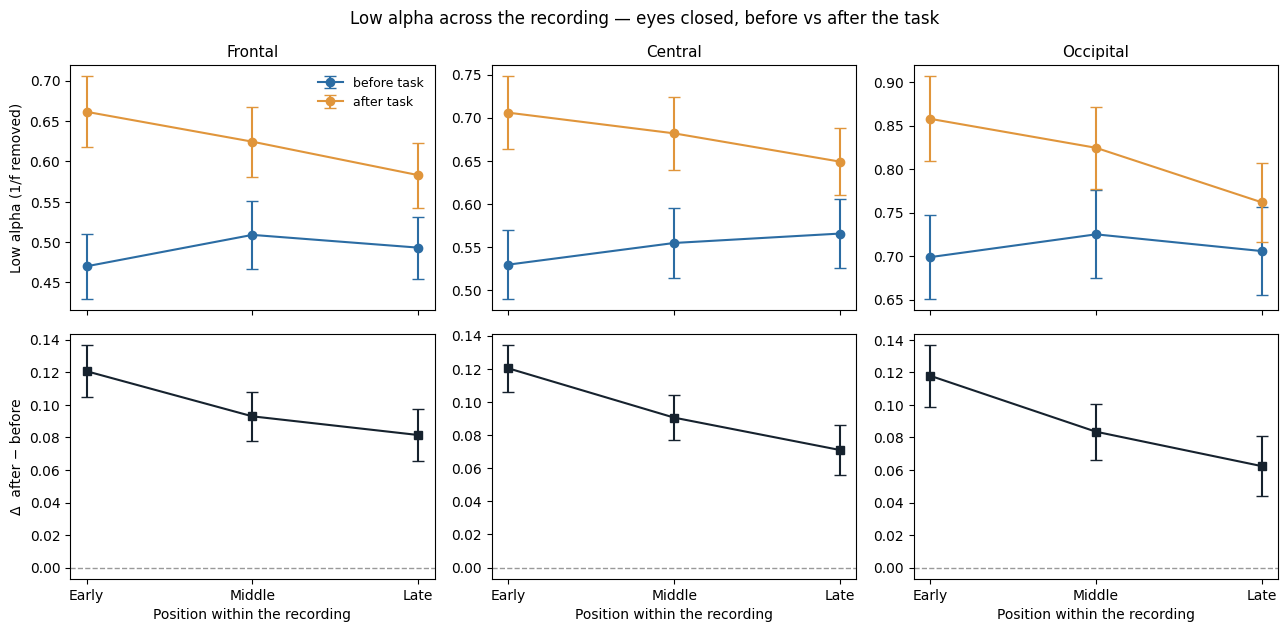

In [5]:
import matplotlib.pyplot as plt

PART_EN = ['Early', 'Middle', 'Late']

def med_ci(s):
    """ค่ากลางพร้อมช่วงความเชื่อมั่นโดยประมาณ"""
    s = np.asarray(s, float)
    q1, q3 = np.percentile(s, [25, 75])
    return np.median(s), 1.57 * (q3 - q1) / np.sqrt(len(s))

fig, axes = plt.subplots(2, 3, figsize=(13, 6.4), sharex=True)

for j, reg in enumerate(REG):
    ax = axes[0, j]
    for cond, col, lab in [('pre', '#2B6CA3', 'before task'),
                           ('post', '#E0953B', 'after task')]:
        g = d[(d.condition == cond) & (d.region == reg)]
        m = [med_ci(g[g.part == p].low_alpha_corr) for p in range(3)]
        ax.errorbar(range(3), [x[0] for x in m], yerr=[x[1] for x in m],
                    marker='o', color=col, capsize=4, label=lab)
    ax.set_title(reg.capitalize(), fontsize=11)
    if j == 0:
        ax.set_ylabel('Low alpha (1/f removed)')
        ax.legend(frameon=False, fontsize=9)

    ax = axes[1, j]
    gg = w[w.region == reg]
    m = [med_ci(gg[gg.part == p].delta) for p in range(3)]
    ax.errorbar(range(3), [x[0] for x in m], yerr=[x[1] for x in m],
                marker='s', color='#16222E', capsize=4)
    ax.axhline(0, color='#999999', lw=1, ls='--')
    ax.set_xticks(range(3)); ax.set_xticklabels(PART_EN)
    ax.set_xlabel('Position within the recording')
    if j == 0:
        ax.set_ylabel('Δ  after − before')

fig.suptitle('Low alpha across the recording — eyes closed, before vs after the task',
             fontsize=12)
plt.tight_layout()
plt.savefig('outputs/nb5f_three_parts.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
print('\nทดสอบ 4 · ความชัน post ต่างจาก pre ในคนเดียวกันไหม\n')
sl = (d.groupby(['subject', 'condition', 'region'])[['part', 'low_alpha_corr']]
        .apply(lambda x: linregress(x.part, x.low_alpha_corr).slope if len(x) == 3 else np.nan,
               include_groups=False)
        .rename('slope').reset_index())
sw = sl.pivot_table(index=['subject', 'region'], columns='condition',
                    values='slope').dropna().reset_index()
for reg in REG:
    g = sw[sw.region == reg]
    p = wilcoxon(g.post, g.pre).pvalue
    print(f'  {reg:<11}n={len(g):>4}  pre {g.pre.median():+.4f}  post {g.post.median():+.4f}  '
          f'ต่าง {np.median(g.post - g.pre):+.4f}  p_bonf={min(p*3, 1):.2g}')


ทดสอบ 4 · ความชัน post ต่างจาก pre ในคนเดียวกันไหม

  frontal    n= 594  pre +0.0080  post -0.0137  ต่าง -0.0207  p_bonf=3.6e-06
  central    n= 594  pre +0.0128  post -0.0139  ต่าง -0.0227  p_bonf=1.1e-09
  occipital  n= 594  pre +0.0053  post -0.0264  ต่าง -0.0279  p_bonf=4.6e-10
